# **📈 Predict Order Profit: Sales ML Models**


**What this notebook does (beginner friendly):**
1. Load & understand the Indian e-commerce sales data (15,000 orders)
2. Clean data and explore it with charts (EDA)
3. Create simple new features (month, day of week)
4. Train **6 models** from a simple baseline to the best one
5. Compare them using R², MAE and RMSE
6. Tune the best model, check feature importance, and write a conclusion

**Goal:** Predict `Profit_INR` (profit of an order) — a **regression** problem.

## **1. Import Libraries**

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_style('whitegrid')

## **2. Load the Data**

In [2]:
import os
# Works on Kaggle and locally: change the path if your file is elsewhere
path = next((p for p in ['/kaggle/input/datasets/vigneshpgd/indian-retail-sales-analytics-dataset/sales_data.csv', 'sales_data.csv', '/mnt/user-data/uploads/sales_data.csv'] if os.path.exists(p)), None)
if path is None:   # on Kaggle, find the file automatically
    for root, _, files in os.walk('/kaggle/input'):
        for f in files:
            if f == 'sales_data.csv': path = os.path.join(root, f)

df = pd.read_csv(path, parse_dates=['Order_Date'])
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (15000, 22)


,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,...,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Returned,Customer_Satisfaction,Payment_Method
0,ORD111444,2024-01-01,CUST10128,West,Pune,Corporate,Online,Home & Kitchen,Appliances,P1046,...,0.00,654.30,0.00,654.30,387.43,266.87,1,No,4,Debit Card
1,ORD102034,2024-01-01,CUST10316,West,Ahmedabad,Corporate,Online,Beauty,Personal Care,P1048,...,0.10,1711.99,171.20,1540.79,874.52,666.27,6,No,3,UPI
2,ORD106623,2024-01-01,CUST11764,South,Chennai,Consumer,Online,Home & Kitchen,Cookware,P1066,...,0.05,5904.75,295.24,5609.51,3095.78,2513.74,3,No,3,Net Banking
3,ORD113951,2024-01-01,CUST12447,Central,Raipur,Consumer,Online,Home & Kitchen,Decor,P1057,...,0.15,1406.48,210.97,1195.51,720.77,474.74,4,No,3,Net Banking
4,ORD105177,2024-01-01,CUST10691,North,Chandigarh,Consumer,Online,Home & Kitchen,Decor,P1023,...,0.15,1522.20,228.33,1293.87,820.70,473.17,6,No,3,Credit Card


## **3. Data Understanding & Cleaning**
We check data types, missing values and duplicates.

In [3]:
df.info()
print('\nMissing values:', df.isna().sum().sum())
print('Duplicate orders:', df.duplicated('Order_ID').sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Order_ID               15000 non-null  object        
 1   Order_Date             15000 non-null  datetime64[ns]
 2   Customer_ID            15000 non-null  object        
 3   Region                 15000 non-null  object        
 4   City                   15000 non-null  object        
 5   Segment                15000 non-null  object        
 6   Channel                15000 non-null  object        
 7   Category               15000 non-null  object        
 8   Subcategory            15000 non-null  object        
 9   Product_ID             15000 non-null  object        
 10  Quantity               15000 non-null  int64         
 11  Unit_Price_INR         15000 non-null  float64       
 12  Discount               15000 non-null  float64       
 13  S

,count,mean,min,25%,50%,75%,max,std
Order_Date,15000,2025-01-01 05:42:31.680000,2024-01-01 00:00:00,2024-07-01 00:00:00,2025-01-03 00:00:00,2025-07-05 00:00:00,2025-12-31 00:00:00,NaN
Quantity,15000.0,3.991333,1.0,2.0,4.0,6.0,7.0,1.99337
Unit_Price_INR,15000.0,1347.45306,150.0,708.49,1092.605,1692.4275,18616.06,973.90804
Discount,15000.0,0.10663,0.0,0.05,0.1,0.15,0.3,0.087742
Sales_INR,15000.0,5396.765599,150.0,2033.355,3901.345,6949.4025,130312.42,5225.206681
Discount_Amount_INR,15000.0,578.66473,0.0,17.455,298.305,745.0525,13031.24,863.70892
Net_Sales_INR,15000.0,4818.100912,119.78,1793.36,3462.51,6230.4825,117281.18,4700.051718
Cost_INR,15000.0,2960.555138,75.11,1090.0925,2110.155,3812.5575,70176.38,2919.123008
Profit_INR,15000.0,1818.571167,39.23,663.1675,1279.1,2334.1925,47104.8,1821.210884
Shipping_Days,15000.0,3.678133,1.0,2.0,4.0,5.0,8.0,1.669228


**Observation:** No missing values and no duplicate orders — the data is clean. 

### **⚠️ Avoiding data leakage**
`Profit = Net_Sales − Cost`. If we give `Cost_INR`, `Net_Sales_INR` or `Discount_Amount_INR` to the model, it can just do subtraction and the score would be fake. 
So we **drop** them and predict profit using only information like product, price, quantity, discount, region, etc.

## **4. Exploratory Data Analysis (EDA)**

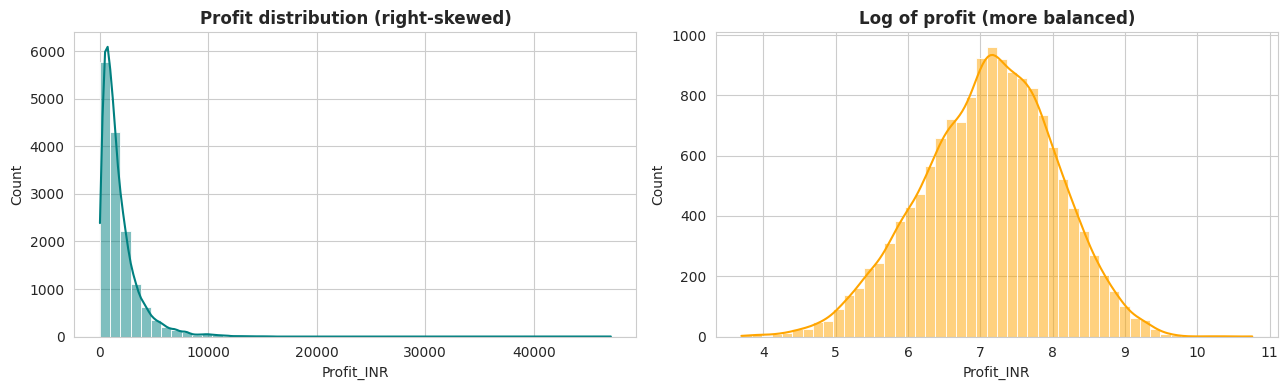

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['Profit_INR'], bins=50, kde=True, ax=ax[0], color='teal')
ax[0].set_title('Profit distribution (right-skewed)',fontweight='bold')
sns.histplot(np.log1p(df['Profit_INR']), bins=50, kde=True, ax=ax[1], color='orange')
ax[1].set_title('Log of profit (more balanced)',fontweight='bold')
plt.tight_layout(); plt.show()

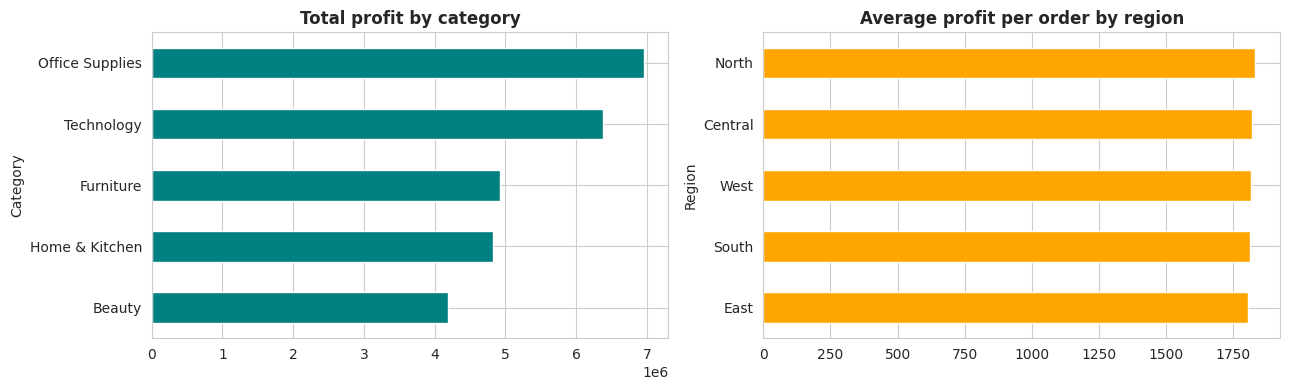

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df.groupby('Category')['Profit_INR'].sum().sort_values().plot.barh(ax=ax[0], color='teal')
ax[0].set_title('Total profit by category',fontweight='bold')
df.groupby('Region')['Profit_INR'].mean().sort_values().plot.barh(ax=ax[1], color='orange')
ax[1].set_title('Average profit per order by region',fontweight='bold')
plt.tight_layout(); plt.show()

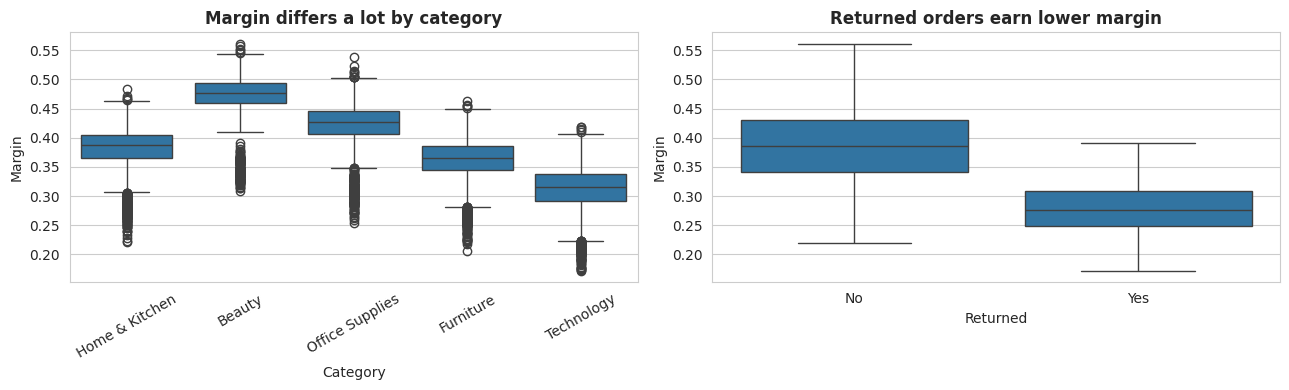

In [6]:
# Profit margin = profit / net sales (how much % we keep)
df['Margin'] = df['Profit_INR'] / df['Net_Sales_INR']
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x='Category', y='Margin', ax=ax[0]); ax[0].tick_params(axis='x', rotation=30)
ax[0].set_title('Margin differs a lot by category',fontweight='bold')
sns.boxplot(data=df, x='Returned', y='Margin', ax=ax[1]); ax[1].set_title('Returned orders earn lower margin',fontweight='bold')
plt.tight_layout(); plt.show()

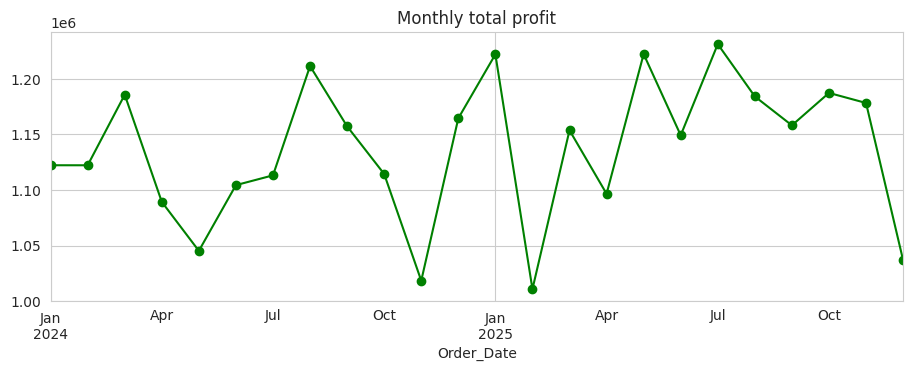

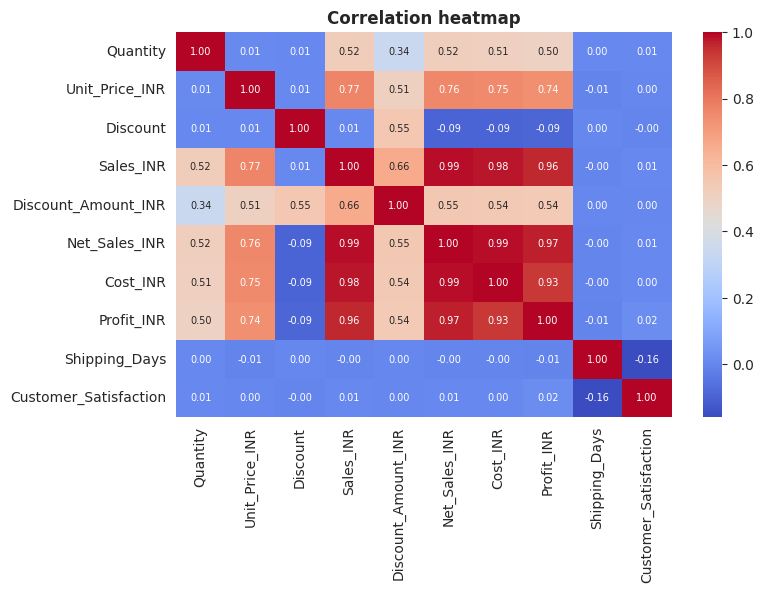

In [7]:
monthly = df.set_index('Order_Date')['Profit_INR'].resample('MS').sum()
monthly.plot(figsize=(11, 3.5), marker='o', color='green', title='Monthly total profit')
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(df.select_dtypes('number').drop(columns='Margin').corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.title('Correlation heatmap',fontweight='bold'); plt.show()

**Key insights**
- Profit is right-skewed: a few big orders earn a lot.
- Margin depends mainly on **Category** (Beauty highest, Technology lowest) and whether the order was **Returned**.
- Profit grows with order value (`Sales_INR`) — price × quantity matters most.

## **5. Feature Engineering**
We pull **Month** and **Day of week** out of the order date and drop columns that leak the answer or are only IDs.

In [8]:
df['Month'] = df['Order_Date'].dt.month
df['DayOfWeek'] = df['Order_Date'].dt.dayofweek

drop_cols = ['Order_ID', 'Customer_ID', 'Product_ID', 'Order_Date', 'City',        # IDs / too many values
             'Cost_INR', 'Net_Sales_INR', 'Discount_Amount_INR', 'Margin']          # leak the answer

target = 'Profit_INR'
X = df.drop(columns=drop_cols + [target])
y = df[target]

cat_cols = X.select_dtypes('object').columns.tolist()
num_cols = X.select_dtypes('number').columns.tolist()
print('Categorical:', cat_cols); print('Numeric:', num_cols)

Categorical: ['Region', 'Segment', 'Channel', 'Category', 'Subcategory', 'Returned', 'Payment_Method']
Numeric: ['Quantity', 'Unit_Price_INR', 'Discount', 'Sales_INR', 'Shipping_Days', 'Customer_Satisfaction', 'Month', 'DayOfWeek']


## **6. Train / Test Split & Preprocessing**
80% of data to train, 20% to test. Text columns are one-hot encoded, numbers are scaled.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', StandardScaler(), num_cols)])
print(X_train.shape, X_test.shape)

(12000, 15) (3000, 15)


## **7. Train Multiple Models (Baseline → Best)**
| Model | Why we try it |
|---|---|
| Linear Regression | Simple baseline |
| Ridge | Linear + regularization |
| Decision Tree | Learns non-linear rules |
| Random Forest | Many trees, more stable |
| Gradient Boosting | Trees learn from previous errors |
| HistGradientBoosting | Fast, modern boosting |

In [10]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Decision Tree': DecisionTreeRegressor(max_depth=8, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42)}

results, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    results.append({'Model': name,
                    'R2': r2_score(y_test, pred),
                    'MAE': mean_absolute_error(y_test, pred),
                    'RMSE': np.sqrt(mean_squared_error(y_test, pred))})

res = pd.DataFrame(results).sort_values('R2', ascending=False).reset_index(drop=True)
res.round(4)

,Model,R2,MAE,RMSE
0,Gradient Boosting,0.9851,127.9705,216.9683
1,Random Forest,0.9793,132.8114,255.7265
2,HistGradientBoosting,0.9691,133.3810,311.9824
3,Decision Tree,0.9595,194.7627,357.5441
4,Ridge,0.9569,223.8841,368.7433
5,Linear Regression,0.9569,223.9193,368.8093


## **8. Model Comparison**

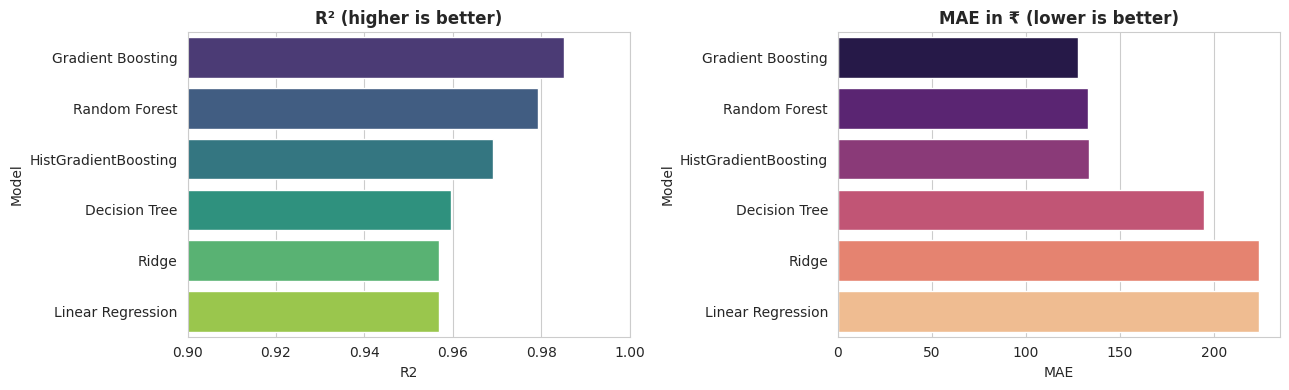

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=res, y='Model', x='R2', ax=ax[0], palette='viridis'); ax[0].set_xlim(0.9, 1); ax[0].set_title('R² (higher is better)',fontweight='bold')
sns.barplot(data=res, y='Model', x='MAE', ax=ax[1], palette='magma'); ax[1].set_title('MAE in ₹ (lower is better)',fontweight='bold')
plt.tight_layout(); plt.show()

## **9. Hyperparameter Tuning (Best Model)**
We tune Gradient Boosting with a small random search and 3-fold cross-validation.

In [12]:
params = {'model__n_estimators': [200, 300, 400],
          'model__learning_rate': [0.05, 0.1, 0.15],
          'model__max_depth': [3, 4, 5],
          'model__subsample': [0.8, 1.0]}

search = RandomizedSearchCV(
    Pipeline([('prep', preprocess), ('model', GradientBoostingRegressor(random_state=42))]),
    params, n_iter=8, cv=3, scoring='r2', random_state=42, n_jobs=-1)
search.fit(X_train, y_train)

best = search.best_estimator_
pred = best.predict(X_test)
print('Best parameters:', search.best_params_)
print(f'Tuned  R2 : {r2_score(y_test, pred):.4f}')
print(f'Tuned  MAE: {mean_absolute_error(y_test, pred):.2f}')
print(f'Tuned  RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.2f}')
cv = cross_val_score(best, X, y, cv=5, scoring='r2')
print(f'5-fold CV R2: {cv.mean():.4f} (+/- {cv.std():.4f})')

Best parameters: {'model__subsample': 1.0, 'model__n_estimators': 200, 'model__max_depth': 3, 'model__learning_rate': 0.1}
Tuned  R2 : 0.9859
Tuned  MAE: 122.42
Tuned  RMSE: 210.92
5-fold CV R2: 0.9778 (+/- 0.0097)


## **10. Check the Predictions**

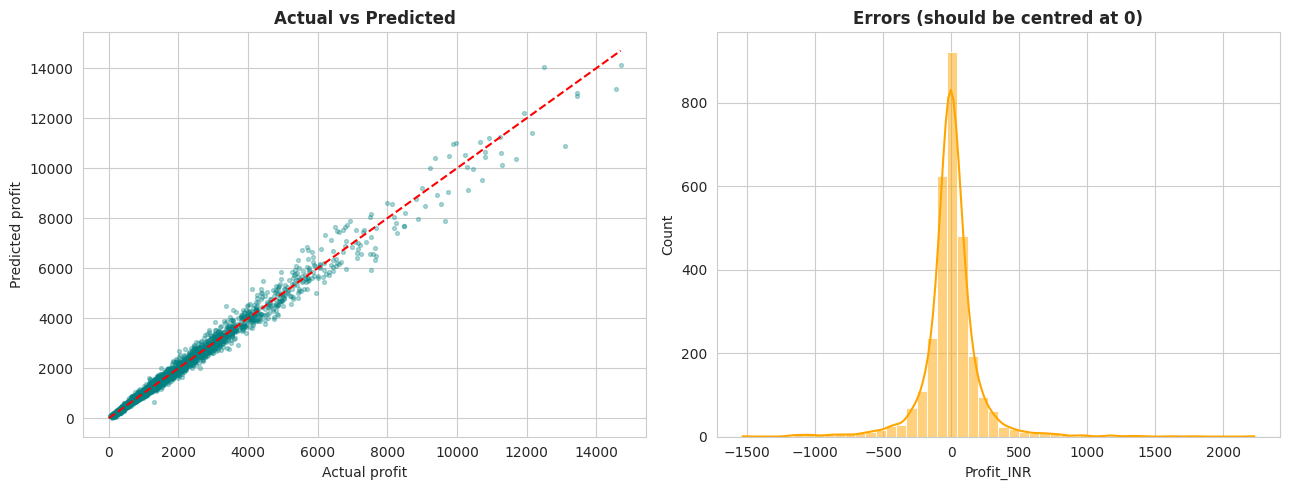

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, pred, alpha=0.3, s=8, color='teal')
ax[0].plot([0, y_test.max()], [0, y_test.max()], 'r--'); ax[0].set_xlabel('Actual profit'); ax[0].set_ylabel('Predicted profit'); ax[0].set_title('Actual vs Predicted',fontweight='bold')
sns.histplot(y_test - pred, bins=50, kde=True, ax=ax[1], color='orange'); ax[1].set_title('Errors (should be centred at 0)',fontweight='bold')
plt.tight_layout(); plt.show()

## **11. Feature Importance**
Which columns helped the model the most?

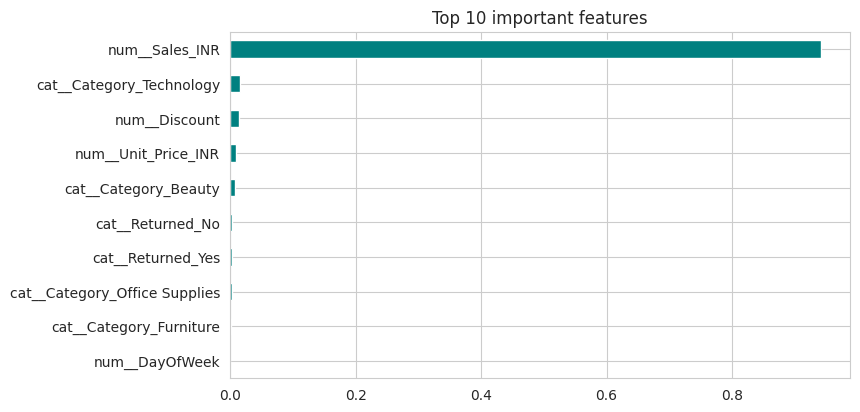

In [14]:
names = best.named_steps['prep'].get_feature_names_out()
imp = pd.Series(best.named_steps['model'].feature_importances_, index=names).sort_values(ascending=False).head(10)
imp.sort_values().plot.barh(figsize=(8, 4.5), color='teal', title='Top 10 important features')
plt.show()

## **12. Conclusion**
- **Problem:** Predict the profit of an order from product, price, quantity, discount, region, channel and other order details.
- **Data:** 15,000 clean orders (no missing values / duplicates). Columns that reveal the answer (`Cost_INR`, `Net_Sales_INR`, `Discount_Amount_INR`) were removed to **avoid data leakage**, so the score is honest.
- **Models compared:** Linear Regression, Ridge, Decision Tree, Random Forest, Gradient Boosting and HistGradientBoosting.
- **Result:** **Gradient Boosting** was the best model (R² ≈ 0.985), followed by Random Forest (≈ 0.979), well above the linear baseline (≈ 0.957). After tuning, it reached **R² ≈ 0.986** with an average error (MAE) of about **₹122** on orders averaging ≈ ₹1,800 profit. 5-fold cross-validation (R² ≈ 0.978) confirms the score is stable.
- **Key drivers:** order value (`Sales_INR`), product **Category/Subcategory** (margin differs), **Discount**, and whether the order was **Returned**.
- **Business tip:** Push high-margin categories (Beauty, Office Supplies), keep discounts under control and reduce returns to protect profit.
- **Next steps:** Try XGBoost / LightGBM, add customer-level features, or predict profit margin (%) instead of ₹.

🙏 *If you found this notebook useful, please upvote!*